In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import pandas as pd

df = pd.read_csv("/content/Week6_Feature_Engineered_Dataset.csv")

print("Dataset uploaded and loaded successfully!")
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

display(df.head())

Dataset uploaded and loaded successfully!
Dataset Shape: (12500, 79)
Number of Rows: 12500
Number of Columns: 79


,Patient_ID,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,...,Anti_OmpC,pANCA,Anti_tissue_transglutaminase,anti_Scl_70,Anti_Mi2,Anti_parietal_cell,Progesterone_antibodies,Gender_Female,Gender_Male,Diagnosis_Encoded
0,1,0.712121,Female,Linear IgA disease,0.218487,0.016667,0.424000,0.596429,0.828276,0.966667,...,0,0,0,0,0,0,0,1,0,65
1,2,0.651515,Male,Dermatomyositis,0.890756,0.612500,0.630667,0.456429,0.661887,0.656667,...,0,0,0,0,1,0,0,0,1,31
2,3,0.363636,Male,Ord's thyroiditis,0.050420,0.170833,0.488000,0.457857,0.441814,0.571667,...,0,0,0,0,0,0,0,0,1,81
3,4,0.409091,Female,Restless legs syndrome,0.092437,0.445833,0.661333,0.292857,0.364788,0.236667,...,0,0,0,0,0,0,0,1,0,93
4,5,0.909091,Female,Autoimmune polyendocrine syndrome type 2 (APS2),0.252101,0.575000,0.161333,0.112857,0.605202,0.645000,...,0,0,0,0,0,0,0,1,0,15


In [5]:

# Target variable
y = df["Diagnosis_Encoded"]

# Select numerical input features
exclude_columns = ["Patient_ID", "Diagnosis_Encoded"]

feature_cols = [
    col for col in df.select_dtypes(include=np.number).columns
        if col not in exclude_columns
        ]
X = df[feature_cols].copy()

X = X.loc[:, X.nunique() > 1]

X = X.fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Target variable: Diagnosis_Encoded")
print("Number of input features:", X.shape[1])
print("Prepared data shape:", X_scaled.shape)
print("Missing values:", np.isnan(X_scaled).sum())

Target variable: Diagnosis_Encoded
Number of input features: 75
Prepared data shape: (12500, 75)
Missing values: 0


In [7]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

selector = SelectKBest(
score_func=lambda X, y: mutual_info_classif(
            X, y, random_state=42
                ),
                    k=min(10, X.shape[1])
                    )

selector.fit(X_scaled, y)

feature_scores = pd.DataFrame({
                        "Feature": X.columns,
                            "Score": selector.scores_,
                                "Selected": selector.get_support()
                                })

feature_scores = feature_scores.sort_values(
                                    by="Score", ascending=False
                                    ).reset_index(drop=True)

print("Top 10 Selected Features:")
display(feature_scores.head(10))

selected_features = X.columns[selector.get_support()]
X_selected = X_scaled[:, selector.get_support()]

print("Original number of features:", X.shape[1])
print("Selected number of features:", X_selected.shape[1])

Top 10 Selected Features:


,Feature,Score,Selected
0,ACPA,0.506712,True
1,CRP,0.499776,True
2,Sickness_Duration_Months,0.481592,True
3,Hemoglobin,0.330738,True
4,RBC_Count,0.322760,True
5,ESR,0.318682,True
6,Hematocrit,0.289430,True
7,MBL_Level,0.249728,True
8,Esbach,0.224240,True
9,ANA,0.217743,True


Original number of features: 75
Selected number of features: 10


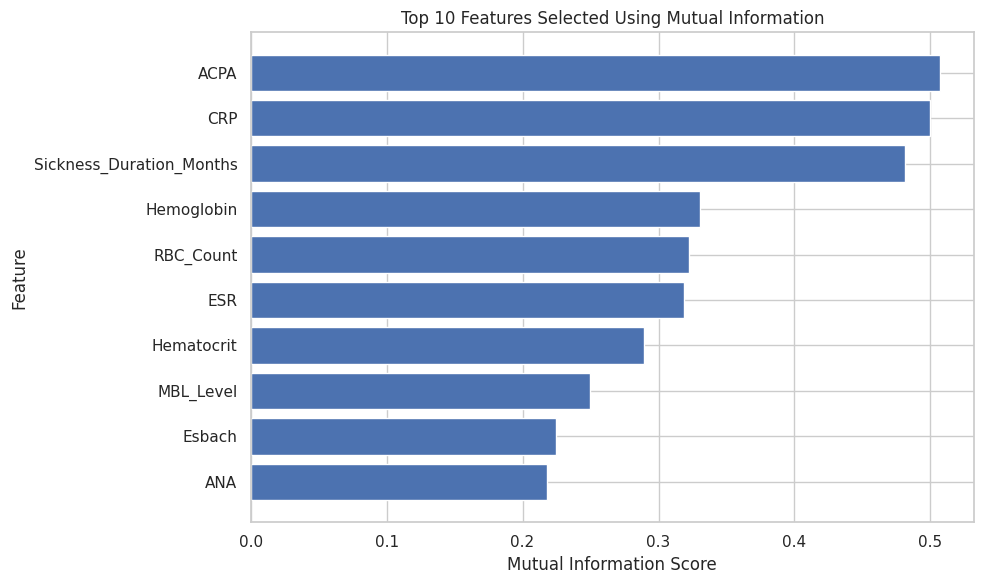

In [8]:
top_features = feature_scores.head(10).sort_values("Score")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Score"])

plt.title("Top 10 Features Selected Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [9]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Original number of features:", X_scaled.shape[1])
print("Components needed for 95% variance:", n_components_95)
print(
    "Variance retained:",
        round(cumulative_variance[n_components_95 - 1] * 100, 2),
            "%"
            )

pca_reduced = PCA(n_components=n_components_95)
X_reduced = pca_reduced.fit_transform(X_scaled)

print("Shape before PCA:", X_scaled.shape)
print("Shape after PCA:", X_reduced.shape)

Original number of features: 75
Components needed for 95% variance: 54
Variance retained: 95.02 %
Shape before PCA: (12500, 75)
Shape after PCA: (12500, 54)


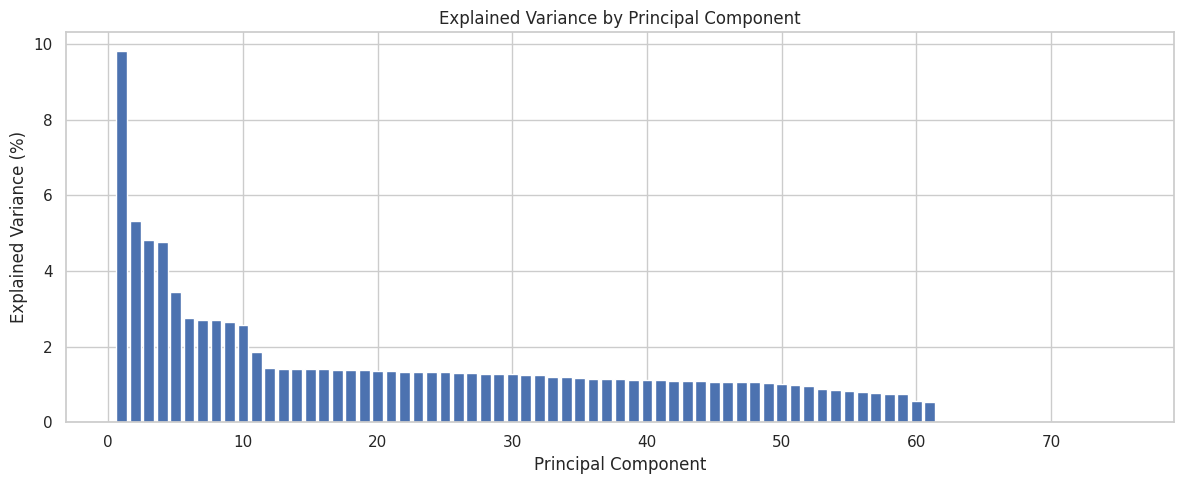

In [10]:
components = np.arange(1, len(explained_variance) + 1)

plt.figure(figsize=(12, 5))
plt.bar(components, explained_variance * 100)

plt.title("Explained Variance by Principal Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")

plt.tight_layout()
plt.show()

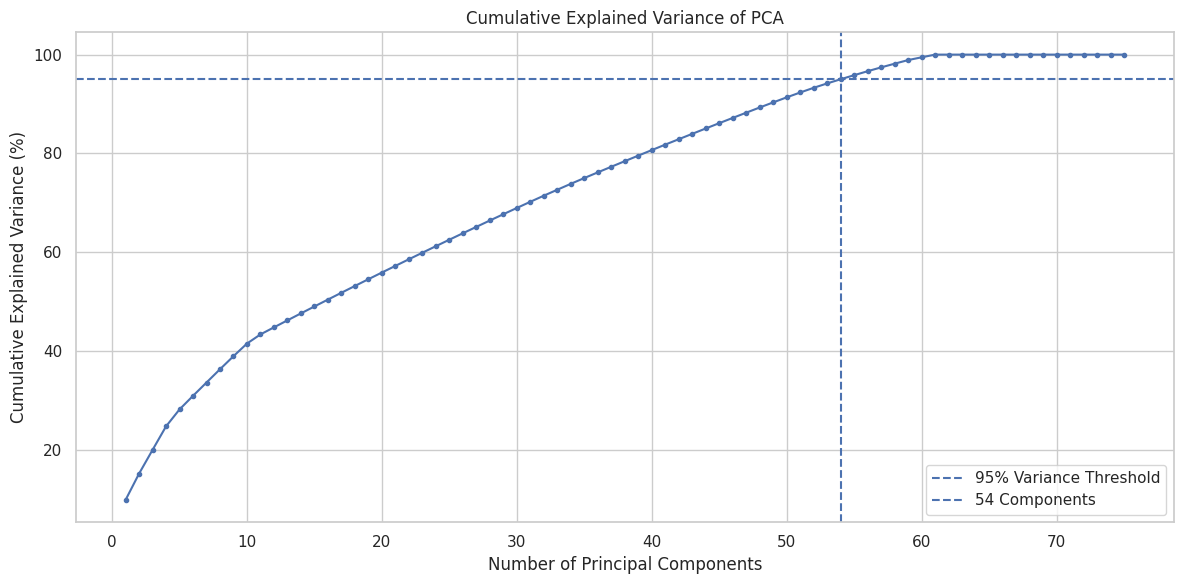

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    components,
        cumulative_variance * 100,
            marker="o",
                markersize=3
                )

plt.axhline( y=95, linestyle="--", label="95% Variance Threshold")

plt.axvline( x=n_components_95, linestyle="--",
                                        label=f"{n_components_95} Components"
                                        )

plt.title("Cumulative Explained Variance of PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:

comparison = pd.DataFrame({ "Method": ["Original Dataset", "Feature Selection","PCA"],
                           "Number of Features": [ X.shape[1],X_selected.shape[1],X_reduced.shape[1]],
                            "Variance Retained (%)": [100.0,np.nan,  round( pca_reduced.explained_variance_ratio_.sum() * 100,2) ] })

display(comparison)

,Method,Number of Features,Variance Retained (%)
0,Original Dataset,75,100.00
1,Feature Selection,10,NaN
2,PCA,54,95.02


In [15]:
reduced_df = pd.DataFrame(
      X_reduced,
          columns=[f"PC{i+1}" for i in range(n_components_95)]
          )

reduced_df["Diagnosis_Encoded"] = y.reset_index(drop=True)

reduced_df.to_csv( "Week7_PCA_Reduced_Dataset.csv", index=False)

feature_scores.to_csv( "Week7_Feature_Selection_Scores.csv",index=False)

print("Week 7 completed successfully!")
print("Saved: Week7_PCA_Reduced_Dataset.csv")
print("Saved: Week7_Feature_Selection_Scores.csv")


Week 7 completed successfully!
Saved: Week7_PCA_Reduced_Dataset.csv
Saved: Week7_Feature_Selection_Scores.csv
